# Day 3 - Transfer learning with ResNet18

**Question:** how do ImageNet-pretrained features compare with your custom CNN?

You will run two stages:
- **Frozen head:** keep the pretrained backbone and BatchNorm statistics fixed; train a new five-class head for six epochs.
- **Full fine-tuning:** start from the best frozen-head checkpoint, unfreeze every layer, and train for six more epochs at a lower learning rate.

The fine-tuned model receives a cumulative 12-epoch budget. The head-only result
receives six epochs. Your Day 2 CNNs each received 12 epochs. These budgets and
cumulative training times are documented in the comparison rather than hidden.
ResNet18 also benefits from prior ImageNet training.

## Before running

1. Select **Runtime -> Change runtime type -> T4 GPU**, if available.
2. Keep your latest `day2_backup (1).zip` available on your computer.
3. Run the cells in order. Upload that ZIP when the restoration cell asks for it.
4. Watch six head-training epochs followed by six fine-tuning epochs.
5. Complete your observations, download `day3_backup.zip`, and download this notebook with outputs using Colab's top **File** menu.

Today's scores use validation data. The test set stays reserved for final evaluation.

## 1. Check packages and GPU

Only missing packages are installed. Keep Colab's supplied GPU-compatible
torch/torchvision pair. Setup should print `GPU available: True`.
Deliberate CPU training is supported with `ALLOW_CPU=True`, but is slower.

In [11]:
import importlib.util
import subprocess
import sys
from pathlib import Path

ALLOW_CPU = False
modules = {"Pillow": "PIL", "numpy": "numpy", "matplotlib": "matplotlib",
           "torch": "torch", "torchvision": "torchvision", "tensorboard": "tensorboard"}
missing = [package for package, module in modules.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import torch
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
current = Path.cwd()
ROOT = Path("/content/flower-cnn") if IN_COLAB else (current.parent if current.name == "notebooks" else current)
ROOT.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
elif not ALLOW_CPU:
    raise RuntimeError("Select a T4 GPU runtime and rerun setup. If PyTorch still ends in +cpu, use a fresh GPU runtime. For deliberate CPU training, set ALLOW_CPU=True.")

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Load the project helpers

The helper files are included in this notebook. This loads the data pipeline,
the shared training/logging loop, and the new ResNet18 model and stages.

In [12]:
# @title Load the reusable project files
HELPER_SOURCES = {'flower_data.py': '"""Day 1: verified download, image audit, and reproducible split manifests.\n\nRun: python flower_data.py --root .\nOnly Pillow is needed. No training or image modification happens here.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport hashlib\nimport importlib.metadata\nimport json\nimport platform\nimport random\nimport shutil\nimport tarfile\nimport tempfile\nimport urllib.request\nfrom collections import Counter, defaultdict\nfrom pathlib import Path, PurePosixPath\n\nfrom PIL import Image, ImageDraw, ImageOps, UnidentifiedImageError\n\nDATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"\nARCHIVE_SHA256 = "4c54ace7911aaffe13a365c34f650e71dd5bf1be0a58b464e5a7183e3e595d9c"\nARCHIVE_BYTES = 228813984\nCHECKSUM_SOURCE = "https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/tf_flowers/checksums.tsv"\nCLASS_NAMES = ("daisy", "dandelion", "roses", "sunflowers", "tulips")\nSPLITS = ("train", "val", "test")\nMANIFEST_FIELDS = ("relative_path", "class_name", "label", "width", "height", "file_sha256", "pixel_sha256", "split")\n\n\ndef sha256_file(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef download_dataset(raw_dir: Path) -> Path:\n    """Verify the official archive before extracting regular files only."""\n    raw_dir = Path(raw_dir).resolve()\n    raw_dir.mkdir(parents=True, exist_ok=True)\n    dataset_dir = raw_dir / "flower_photos"\n    marker = dataset_dir / ".verified_archive_sha256"\n    if dataset_dir.exists():\n        if marker.is_file() and marker.read_text().strip() == ARCHIVE_SHA256:\n            return dataset_dir\n        raise ValueError(f"Unverified existing directory: {dataset_dir}. Use a new --root.")\n\n    archive = raw_dir / "flower_photos.tgz"\n    if not archive.exists():\n        partial = archive.with_suffix(".tgz.part")\n        received, next_notice = 0, 20 * 1024 * 1024\n        print(f"Downloading {ARCHIVE_BYTES / 1024**2:.1f} MiB of flower images...", flush=True)\n        request = urllib.request.Request(DATASET_URL, headers={"User-Agent": "flower-cnn-day1/1.0"})\n        with urllib.request.urlopen(request, timeout=60) as response, partial.open("wb") as out:\n            for block in iter(lambda: response.read(1024 * 1024), b""):\n                out.write(block)\n                received += len(block)\n                if received >= next_notice:\n                    print(f"  {received / 1024**2:.0f} MiB downloaded", flush=True)\n                    next_notice += 20 * 1024 * 1024\n        if partial.stat().st_size != ARCHIVE_BYTES or sha256_file(partial) != ARCHIVE_SHA256:\n            partial.unlink(missing_ok=True)\n            raise ValueError("Dataset download failed its size/SHA-256 check; rerun to retry.")\n        partial.replace(archive)\n    if archive.stat().st_size != ARCHIVE_BYTES or sha256_file(archive) != ARCHIVE_SHA256:\n        raise ValueError(f"Cached archive checksum mismatch: {archive}. Rename it and retry.")\n\n    # Staging keeps a partially extracted dataset from being mistaken for a complete one.\n    with tempfile.TemporaryDirectory(prefix="extract-", dir=raw_dir) as temp:\n        staging = Path(temp).resolve()\n        with tarfile.open(archive, "r:gz") as source:\n            for member in source:\n                parts = PurePosixPath(member.name).parts\n                if not parts or parts[0] != "flower_photos" or ".." in parts or "\\\\" in member.name:\n                    raise ValueError(f"Unexpected archive path: {member.name}")\n                target = staging.joinpath(*parts).resolve()\n                if not target.is_relative_to(staging):\n                    raise ValueError(f"Archive path escapes staging: {member.name}")\n                if member.isdir():\n                    target.mkdir(parents=True, exist_ok=True)\n                elif member.isfile():\n                    target.parent.mkdir(parents=True, exist_ok=True)\n                    with source.extractfile(member) as incoming, target.open("wb") as out:\n                        shutil.copyfileobj(incoming, out)\n                else:\n                    raise ValueError(f"Unsupported archive member: {member.name}")\n        extracted = staging / "flower_photos"\n        if not all((extracted / name).is_dir() for name in CLASS_NAMES):\n            raise ValueError("Archive does not contain all five flower categories.")\n        (extracted / ".verified_archive_sha256").write_text(ARCHIVE_SHA256 + "\\n")\n        extracted.rename(dataset_dir)\n    return dataset_dir\n\n\ndef audit_images(dataset_dir: Path) -> tuple[list[dict], dict]:\n    """Decode every image; keep one copy per exact decoded RGB image.\n\n    Identical images with conflicting class labels are all excluded for review.\n    This detects exact duplicates, not crops or other near duplicates.\n    """\n    candidates, corrupt = [], []\n    dataset_dir = Path(dataset_dir)\n    for label, class_name in enumerate(CLASS_NAMES):\n        class_dir = dataset_dir / class_name\n        if not class_dir.is_dir():\n            raise ValueError(f"Missing class directory: {class_dir}")\n        for path in sorted(class_dir.iterdir()):\n            if not path.is_file() or path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:\n                continue\n            relative = path.relative_to(dataset_dir).as_posix()\n            try:\n                with Image.open(path) as image:\n                    rgb = ImageOps.exif_transpose(image).convert("RGB")\n                    rgb.load()\n                    width, height = rgb.size\n                    pixels = hashlib.sha256(f"{width}x{height}:RGB:".encode() + rgb.tobytes()).hexdigest()\n                candidates.append({"relative_path": relative, "class_name": class_name, "label": label,\n                                   "width": width, "height": height, "file_sha256": sha256_file(path),\n                                   "pixel_sha256": pixels})\n            except (OSError, ValueError, UnidentifiedImageError, Image.DecompressionBombError) as error:\n                corrupt.append({"relative_path": relative, "error": str(error)})\n\n    groups = defaultdict(list)\n    for row in candidates:\n        groups[row["pixel_sha256"]].append(row)\n    clean, duplicates, conflicts = [], [], []\n    for group in groups.values():\n        if len({row["label"] for row in group}) > 1:\n            conflicts.append([row["relative_path"] for row in group])\n            continue\n        clean.append(group[0])\n        duplicates.extend({"kept": group[0]["relative_path"], "excluded": row["relative_path"]} for row in group[1:])\n    clean.sort(key=lambda row: row["relative_path"])\n    if any(not any(row["class_name"] == name for row in clean) for name in CLASS_NAMES):\n        raise ValueError("Every class must contain readable, non-conflicting images.")\n    audit = {"images_scanned": len(candidates) + len(corrupt), "readable_images": len(candidates),\n             "usable_images": len(clean), "corrupt_images": corrupt, "excluded_duplicates": duplicates,\n             "conflicting_label_groups": conflicts, "duplicate_detection": "Exact decoded RGB pixels; near duplicates are not detected."}\n    return clean, audit\n\n\ndef stratified_split(rows: list[dict], seed: int = 42) -> list[dict]:\n    """Assign approximately 70/15/15 percent within each class, deterministically."""\n    grouped = defaultdict(list)\n    for row in rows:\n        grouped[row["class_name"]].append(dict(row))\n    result = []\n    for class_name in sorted(grouped):\n        group = sorted(grouped[class_name], key=lambda row: row["relative_path"])\n        if len(group) < 7:\n            raise ValueError(f"Need at least 7 usable images in {class_name} for three splits.")\n        random.Random(f"{seed}:{class_name}").shuffle(group)\n        n_val = int(len(group) * 0.15 + 0.5)\n        n_test = int(len(group) * 0.15 + 0.5)\n        n_train = len(group) - n_val - n_test\n        for index, row in enumerate(group):\n            row["split"] = "train" if index < n_train else "val" if index < n_train + n_val else "test"\n            result.append(row)\n    return sorted(result, key=lambda row: row["relative_path"])\n\n\ndef validate_splits(rows: list[dict]) -> None:\n    if not rows:\n        raise ValueError("Split manifest cannot be empty.")\n    if len({row["relative_path"] for row in rows}) != len(rows):\n        raise ValueError("A file appears more than once in the split manifest.")\n    if len({row["pixel_sha256"] for row in rows}) != len(rows):\n        raise ValueError("Duplicate decoded images remain in the split manifest.")\n    for row in rows:\n        if row["split"] not in SPLITS:\n            raise ValueError(f"Unknown split: {row[\'split\']}")\n        if row["class_name"] not in CLASS_NAMES or int(row["label"]) != CLASS_NAMES.index(row["class_name"]):\n            raise ValueError("Class name and numeric label do not match.")\n    for name in CLASS_NAMES:\n        if {row["split"] for row in rows if row["class_name"] == name} != set(SPLITS):\n            raise ValueError(f"Class {name} is missing from a split.")\n\n\ndef save_sample_grid(rows: list[dict], dataset_dir: Path, destination: Path, seed: int = 42) -> None:\n    """Only training images are shown; labels are folder labels, not predictions."""\n    tile_width, tile_height = 190, 166\n    canvas = Image.new("RGB", (5 * tile_width, 5 * tile_height + 40), "#f5f7fb")\n    draw = ImageDraw.Draw(canvas)\n    draw.text((12, 12), "Training samples: five images per class", fill="#17253c")\n    for class_index, class_name in enumerate(CLASS_NAMES):\n        group = [row for row in rows if row["class_name"] == class_name and row["split"] == "train"]\n        selection = random.Random(f"{seed}:{class_name}:preview").sample(group, min(5, len(group)))\n        for column, row in enumerate(selection):\n            x, y = column * tile_width + 8, class_index * tile_height + 40\n            with Image.open(dataset_dir / row["relative_path"]) as image:\n                thumbnail = ImageOps.fit(ImageOps.exif_transpose(image).convert("RGB"), (174, 134))\n                canvas.paste(thumbnail, (x, y))\n            draw.text((x, y + 138), class_name, fill="#17253c")\n    canvas.save(destination)\n\n\ndef write_json(path: Path, value) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2) + "\\n", encoding="utf-8")\n\n\ndef record_environment(destination: Path) -> None:\n    packages = {}\n    for name in ("Pillow", "numpy", "matplotlib", "torch", "torchvision"):\n        try:\n            packages[name] = importlib.metadata.version(name)\n        except importlib.metadata.PackageNotFoundError:\n            packages[name] = None\n    write_json(destination, {"python": platform.python_version(), "platform": platform.platform(), "packages": packages})\n\n\ndef prepare_project(root: Path, seed: int = 42, dataset_dir: Path | None = None) -> dict:\n    root = Path(root).resolve()\n    dataset_dir = Path(dataset_dir).resolve() if dataset_dir else download_dataset(root / "data" / "raw")\n    print("Auditing images and checking exact duplicates...", flush=True)\n    rows, audit = audit_images(dataset_dir)\n    rows = stratified_split(rows, seed)\n    validate_splits(rows)\n    processed, reports = root / "data" / "processed", root / "outputs" / "day1"\n    processed.mkdir(parents=True, exist_ok=True)\n    reports.mkdir(parents=True, exist_ok=True)\n    manifest = processed / "splits.csv"\n    with manifest.open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=MANIFEST_FIELDS)\n        writer.writeheader()\n        writer.writerows(rows)\n    class_counts = {name: {split: sum(row["class_name"] == name and row["split"] == split for row in rows)\n                           for split in SPLITS} for name in CLASS_NAMES}\n    summary = {"dataset": "Flower Photos", "dataset_url": DATASET_URL, "source_archive_sha256": ARCHIVE_SHA256 if dataset_dir == root / "data" / "raw" / "flower_photos" else None,\n               "dataset_dir": str(dataset_dir), "seed": seed, "split_ratios": {"train": 0.7, "val": 0.15, "test": 0.15},\n               "class_to_idx": {name: label for label, name in enumerate(CLASS_NAMES)},\n               "class_counts": class_counts, "split_counts": dict(Counter(row["split"] for row in rows)),\n               "width_range": [min(row["width"] for row in rows), max(row["width"] for row in rows)],\n               "height_range": [min(row["height"] for row in rows), max(row["height"] for row in rows)],\n               "manifest_sha256": sha256_file(manifest), "audit": audit}\n    write_json(reports / "data_summary.json", summary)\n    write_json(reports / "audit.json", audit)\n    write_json(processed / "class_to_idx.json", summary["class_to_idx"])\n    record_environment(reports / "environment.json")\n    save_sample_grid(rows, dataset_dir, reports / "sample_grid.jpg", seed)\n    lines = ["# Day 1 data audit", "", f"Usable images: {len(rows)}. Seed: {seed}.", "",\n             "| Class | Train | Validation | Test |", "|---|---:|---:|---:|"]\n    lines += [f"| {name} | {counts[\'train\']} | {counts[\'val\']} | {counts[\'test\']} |" for name, counts in class_counts.items()]\n    lines += ["", f"Unreadable files: {len(audit[\'corrupt_images\'])}.",\n              f"Excluded exact duplicates: {len(audit[\'excluded_duplicates\'])}.",\n              f"Conflicting-label groups excluded: {len(audit[\'conflicting_label_groups\'])}.", "",\n              "Manual label review and near-duplicate review are still needed. The class folders provide the labels.",\n              "Only training images appear in sample_grid.jpg. Reuse splits.csv for every experiment.",\n              "No model has been trained; there are no accuracy results yet."]\n    (reports / "data_report.md").write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n    print(json.dumps({"usable_images": len(rows), "split_counts": summary["split_counts"], "report": str(reports / "data_report.md")}, indent=2), flush=True)\n    return summary\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--root", type=Path, default=Path(__file__).resolve().parent)\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--dataset-dir", type=Path, help="Use an already downloaded folder containing the five class directories.")\n    args = parser.parse_args()\n    prepare_project(args.root, args.seed, args.dataset_dir)\n', 'flower_pipeline.py': '"""PyTorch datasets and separate transforms for the saved Day 1 splits."""\n\nfrom __future__ import annotations\n\nimport csv\nimport json\nimport os\nimport random\nfrom pathlib import Path\n\nimport numpy as np\nimport torch\nfrom PIL import Image, ImageOps\nfrom torch.utils.data import DataLoader, Dataset\nfrom torchvision import transforms\n\nfrom flower_data import CLASS_NAMES, sha256_file, validate_splits\n\nIMAGENET_MEAN = (0.485, 0.456, 0.406)\nIMAGENET_STD = (0.229, 0.224, 0.225)\n\n\nclass FlowerDataset(Dataset):\n    def __init__(self, dataset_dir: Path, rows: list[dict], transform):\n        self.dataset_dir = Path(dataset_dir).resolve()\n        self.rows = rows\n        self.transform = transform\n        for row in rows:\n            image_path = (self.dataset_dir / row["relative_path"]).resolve()\n            if not image_path.is_relative_to(self.dataset_dir) or not image_path.is_file():\n                raise ValueError(f"Missing or invalid image path: {image_path}")\n\n    def __len__(self):\n        return len(self.rows)\n\n    def __getitem__(self, index):\n        row = self.rows[index]\n        with Image.open(self.dataset_dir / row["relative_path"]) as source:\n            image = ImageOps.exif_transpose(source).convert("RGB")\n        return self.transform(image), int(row["label"])\n\n\ndef seed_worker(worker_id):\n    worker_seed = torch.initial_seed() % 2**32\n    np.random.seed(worker_seed)\n    random.seed(worker_seed)\n\n\ndef seed_everything(seed=42):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cudnn.deterministic = True\n\n\ndef make_loaders(root: Path, batch_size=32, num_workers=0, augment=False, seed=42, dataset_dir=None):\n    """Baseline training is unaugmented; val/test are always deterministic.\n\n    Start a fresh set of loaders with the same seed for each experiment.\n    Fixed seeds improve repeatability; identical GPU results across machines\n    and library versions are not guaranteed.\n    """\n    root = Path(root).resolve()\n    manifest = root / "data" / "processed" / "splits.csv"\n    summary = json.loads((root / "outputs" / "day1" / "data_summary.json").read_text())\n    if sha256_file(manifest) != summary["manifest_sha256"]:\n        raise ValueError("Split manifest changed since preparation. Restore it or rerun data preparation.")\n    with manifest.open(newline="", encoding="utf-8") as stream:\n        rows = list(csv.DictReader(stream))\n    validate_splits(rows)\n    dataset_dir = Path(dataset_dir) if dataset_dir else root / "data" / "raw" / "flower_photos"\n    normalise = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]\n    evaluation_transform = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), *normalise])\n    train_transform = transforms.Compose([\n        transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),\n        transforms.RandomHorizontalFlip(),\n        transforms.RandomRotation(15),\n        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),\n        *normalise,\n    ]) if augment else evaluation_transform\n    seed_everything(seed)\n    loaders = {}\n    for split in ("train", "val", "test"):\n        dataset = FlowerDataset(dataset_dir, [row for row in rows if row["split"] == split],\n                                train_transform if split == "train" else evaluation_transform)\n        generator = torch.Generator().manual_seed(seed)\n        loaders[split] = DataLoader(dataset, batch_size=batch_size, shuffle=split == "train",\n                                    num_workers=num_workers, pin_memory=torch.cuda.is_available(),\n                                    worker_init_fn=seed_worker, generator=generator, drop_last=False)\n    return loaders, list(CLASS_NAMES)\n\n\ndef save_eda_charts(root: Path):\n    """Standard matplotlib charts of counts and original image dimensions."""\n    root = Path(root)\n    config = root / "outputs" / ".matplotlib"\n    config.mkdir(parents=True, exist_ok=True)\n    os.environ.setdefault("MPLCONFIGDIR", str(config.resolve()))\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n\n    with (root / "data" / "processed" / "splits.csv").open(newline="", encoding="utf-8") as stream:\n        rows = list(csv.DictReader(stream))\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")\n    bottom = np.zeros(len(CLASS_NAMES))\n    for split, colour in zip(("train", "val", "test"), ("#2962d9", "#e3a11a", "#249977")):\n        counts = [sum(row["class_name"] == name and row["split"] == split for row in rows) for name in CLASS_NAMES]\n        axes[0].bar(CLASS_NAMES, counts, bottom=bottom, color=colour, label=split)\n        bottom += np.array(counts)\n    axes[0].set(title="Images per class and split", ylabel="Number of images")\n    axes[0].legend()\n    axes[1].hist([int(row["width"]) for row in rows], bins=25, alpha=0.65, label="Width", color="#2962d9")\n    axes[1].hist([int(row["height"]) for row in rows], bins=25, alpha=0.6, label="Height", color="#249977")\n    axes[1].set(title="Original image dimensions", xlabel="Pixels", ylabel="Number of images")\n    axes[1].legend()\n    destination = root / "outputs" / "day1" / "eda_charts.png"\n    fig.savefig(destination, dpi=150)\n    plt.close(fig)\n    return destination\n', 'flower_training.py': '"""Day 2: custom CNN and paired training/augmentation experiments.\n\nRun: python flower_training.py --root . --epochs 12\nFull training requires CUDA unless --allow-cpu is explicitly supplied.\nBounded CPU checks use --smoke and are saved separately from full experiments.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport hashlib\nimport io\nimport json\nimport math\nimport os\nimport platform\nimport time\nimport zipfile\nfrom datetime import datetime, timezone\nfrom pathlib import Path, PurePosixPath\nfrom itertools import islice\n\nimport torch\nfrom torch import nn\n\nfrom flower_data import CLASS_NAMES, download_dataset, record_environment, sha256_file, validate_splits, write_json\nfrom flower_pipeline import make_loaders, seed_everything\n\nEXPECTED_DAY1_MANIFEST_SHA256 = "4fc79e62cb179ff75a18772ba16f72e091184263e6fb8f4731819bbdc07c2dbb"\nDAY1_REQUIRED = ("data/processed/splits.csv", "data/processed/class_to_idx.json", "outputs/day1/data_summary.json")\n\n\ndef restore_day1_backup(backup: Path, root: Path) -> dict:\n    """Restore known data artifacts only; never execute Python from an archive."""\n    root = Path(root).resolve()\n    with zipfile.ZipFile(backup) as archive:\n        names = archive.namelist()\n        for name in DAY1_REQUIRED:\n            if names.count(name) != 1:\n                raise ValueError(f"Backup must contain exactly one {name}.")\n        selected = [info for info in archive.infolist()\n                    if not info.is_dir() and info.filename.startswith(("data/processed/", "outputs/day1/"))]\n        if any(info.file_size > 20 * 1024**2 for info in selected) or sum(info.file_size for info in selected) > 40 * 1024**2:\n            raise ValueError("Day 1 backup artifacts are unexpectedly large.")\n        contents = {info.filename: archive.read(info) for info in selected}\n        for name in contents:\n            if ".." in PurePosixPath(name).parts or "\\\\" in name:\n                raise ValueError(f"Invalid backup path: {name}")\n        summary = json.loads(contents["outputs/day1/data_summary.json"])\n        manifest_bytes = contents["data/processed/splits.csv"]\n        actual = hashlib.sha256(manifest_bytes).hexdigest()\n        if actual != EXPECTED_DAY1_MANIFEST_SHA256 or actual != summary["manifest_sha256"]:\n            raise ValueError("Backup splits differ from the verified Day 1 splits. Keep the original manifest.")\n        validate_splits(list(csv.DictReader(io.StringIO(manifest_bytes.decode("utf-8")))))\n        expected_mapping = {name: index for index, name in enumerate(CLASS_NAMES)}\n        if json.loads(contents["data/processed/class_to_idx.json"]) != expected_mapping:\n            raise ValueError("Backup class mapping does not match Day 1.")\n        for name, data in contents.items():\n            destination = (root / name).resolve()\n            if not destination.is_relative_to(root):\n                raise ValueError(f"Invalid backup path: {name}")\n            if destination.suffix.lower() not in {".csv", ".json", ".md", ".txt", ".jpg", ".png"}:\n                continue\n            destination.parent.mkdir(parents=True, exist_ok=True)\n            destination.write_bytes(data)\n    return validate_day1(root)\n\n\ndef validate_day1(root: Path) -> dict:\n    root = Path(root)\n    manifest = root / "data/processed/splits.csv"\n    actual = sha256_file(manifest)\n    summary = json.loads((root / "outputs/day1/data_summary.json").read_text(encoding="utf-8"))\n    if actual != EXPECTED_DAY1_MANIFEST_SHA256 or actual != summary["manifest_sha256"]:\n        raise ValueError("Day 1 manifest changed. Restore the verified Day 1 backup.")\n    with manifest.open(newline="", encoding="utf-8") as stream:\n        rows = list(csv.DictReader(stream))\n    validate_splits(rows)\n    mapping = json.loads((root / "data/processed/class_to_idx.json").read_text(encoding="utf-8"))\n    if mapping != {name: index for index, name in enumerate(CLASS_NAMES)}:\n        raise ValueError("Class mapping changed since Day 1.")\n    counts = {split: sum(row["split"] == split for row in rows) for split in ("train", "val", "test")}\n    if counts != summary["split_counts"]:\n        raise ValueError("Recorded split counts do not match the manifest.")\n    return {"manifest_sha256": actual, "class_to_idx": mapping, "split_counts": counts}\n\n\nclass SmallCNN(nn.Module):\n    """Three conv/BatchNorm/ReLU/pool blocks, followed by a small classifier."""\n    def __init__(self, num_classes=5):\n        super().__init__()\n        blocks = []\n        for incoming, outgoing in ((3, 16), (16, 32), (32, 64)):\n            blocks.extend([nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False),\n                           nn.BatchNorm2d(outgoing), nn.ReLU(inplace=True), nn.MaxPool2d(2)])\n        self.features = nn.Sequential(*blocks)\n        self.pool = nn.AdaptiveAvgPool2d((4, 4))\n        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 4 * 4, 128),\n                                        nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, num_classes))\n\n    def forward(self, images):\n        return self.classifier(self.pool(self.features(images)))\n\n\ndef metrics_from_confusion(confusion: torch.Tensor) -> dict:\n    counts = confusion.to(dtype=torch.float64, device="cpu")\n    true_positive = counts.diag()\n    predicted = counts.sum(0)\n    actual = counts.sum(1)\n    precision = torch.where(predicted > 0, true_positive / predicted.clamp_min(1), 0.0)\n    recall = torch.where(actual > 0, true_positive / actual.clamp_min(1), 0.0)\n    denominator = precision + recall\n    f1 = torch.where(denominator > 0, 2 * precision * recall / denominator.clamp_min(1e-15), 0.0)\n    total = counts.sum().item()\n    return {"accuracy": float(true_positive.sum().item() / total) if total else 0.0,\n            "macro_f1": float(f1.mean().item()), "per_class_f1": f1.tolist(), "samples": int(total)}\n\n\ndef run_epoch(model, loader, device, optimizer=None, max_batches=None, log_every=20):\n    training = optimizer is not None\n    model.train(training)\n    confusion = torch.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=torch.int64)\n    total_loss, seen = 0.0, 0\n    criterion = nn.CrossEntropyLoss()\n    started = time.perf_counter()\n    batches = islice(loader, max_batches) if max_batches is not None else loader\n    for index, (images, labels) in enumerate(batches):\n        images = images.to(device, non_blocking=True)\n        labels = labels.to(device, non_blocking=True)\n        if training:\n            optimizer.zero_grad(set_to_none=True)\n        with torch.set_grad_enabled(training):\n            logits = model(images)\n            loss = criterion(logits, labels)\n            if not torch.isfinite(loss):\n                raise FloatingPointError("Training/validation loss is not finite.")\n            if training:\n                loss.backward()\n                optimizer.step()\n        batch_size = labels.size(0)\n        total_loss += loss.item() * batch_size\n        seen += batch_size\n        codes = labels.detach().cpu() * len(CLASS_NAMES) + logits.detach().argmax(1).cpu()\n        confusion += torch.bincount(codes, minlength=len(CLASS_NAMES)**2).reshape(len(CLASS_NAMES), len(CLASS_NAMES))\n        if training and log_every and (index + 1) % log_every == 0:\n            print(f"    train batch {index + 1}/{len(loader)} | loss {total_loss / seen:.4f}", flush=True)\n    if seen == 0:\n        raise ValueError("Epoch received no images.")\n    metrics = metrics_from_confusion(confusion)\n    metrics.update(loss=total_loss / seen, seconds=time.perf_counter() - started)\n    return metrics\n\n\ndef state_fingerprint(state) -> str:\n    digest = hashlib.sha256()\n    for name, tensor in sorted(state.items()):\n        digest.update(name.encode())\n        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())\n    return digest.hexdigest()\n\n\ndef train_one_run(root, directory, run_name, initial_state, config, data_info, augment, model_factory=None):\n    from torch.utils.tensorboard import SummaryWriter\n\n    directory = Path(directory)\n    directory.mkdir(parents=True, exist_ok=False)\n    device = torch.device(config["device"])\n    loaders, _ = make_loaders(root, batch_size=config["batch_size"], num_workers=config["num_workers"],\n                              augment=augment, seed=config["seed"])\n    seed_everything(config["seed"])\n    model = model_factory() if model_factory is not None else SmallCNN()\n    model.load_state_dict(initial_state)\n    model.to(device)\n    optimizer = torch.optim.AdamW((parameter for parameter in model.parameters() if parameter.requires_grad),\n                                  lr=config["learning_rate"], weight_decay=config["weight_decay"])\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"])\n    initial_hash = state_fingerprint(model.state_dict())\n    run_config = {**config, "run": run_name, "augmentation": augment,\n                  "manifest_sha256": data_info["manifest_sha256"], "initial_state_sha256": initial_hash,\n                  "class_to_idx": data_info["class_to_idx"], "selection_metric": "validation_macro_f1",\n                  "selection_tiebreak": "lower_validation_loss", "trainable_parameters": sum(p.numel() for p in model.parameters())}\n    write_json(directory / "config.json", run_config)\n    record_environment(directory / "environment.json")\n    history = []\n    best_score, best_loss, best_epoch = -1.0, math.inf, 0\n    started = time.perf_counter()\n    fields = ("epoch", "learning_rate", "train_loss", "train_accuracy", "train_macro_f1",\n              "val_loss", "val_accuracy", "val_macro_f1", "train_samples", "val_samples", "epoch_seconds")\n    writer = SummaryWriter(log_dir=str(directory / "tensorboard"))\n    try:\n        with (directory / "history.csv").open("w", newline="", encoding="utf-8") as stream:\n            history_writer = csv.DictWriter(stream, fieldnames=fields)\n            history_writer.writeheader()\n            for epoch in range(1, config["epochs"] + 1):\n                learning_rate = optimizer.param_groups[0]["lr"]\n                train = run_epoch(model, loaders["train"], device, optimizer,\n                                  config["max_train_batches"], log_every=config["log_every"])\n                validation = run_epoch(model, loaders["val"], device,\n                                       max_batches=config["max_val_batches"], log_every=0)\n                row = {"epoch": epoch, "learning_rate": learning_rate,\n                       "train_loss": train["loss"], "train_accuracy": train["accuracy"], "train_macro_f1": train["macro_f1"],\n                       "val_loss": validation["loss"], "val_accuracy": validation["accuracy"], "val_macro_f1": validation["macro_f1"],\n                       "train_samples": train["samples"], "val_samples": validation["samples"],\n                       "epoch_seconds": train["seconds"] + validation["seconds"]}\n                history.append(row)\n                history_writer.writerow(row)\n                stream.flush()\n                for stage, metrics in (("train", train), ("val", validation)):\n                    for metric in ("loss", "accuracy", "macro_f1"):\n                        writer.add_scalar(f"{metric}/{stage}", metrics[metric], epoch)\n                writer.add_scalar("learning_rate", learning_rate, epoch)\n                is_best = validation["macro_f1"] > best_score or (validation["macro_f1"] == best_score and validation["loss"] < best_loss)\n                if is_best:\n                    best_score, best_loss, best_epoch = validation["macro_f1"], validation["loss"], epoch\n                    checkpoint = {"model_state": {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()},\n                                  "model_name": config.get("model_name", "SmallCNN"), "num_classes": len(CLASS_NAMES), "epoch": epoch,\n                                  "val_macro_f1": best_score, "val_loss": best_loss, "config": run_config}\n                    pending = directory / "best.pt.tmp"\n                    torch.save(checkpoint, pending)\n                    pending.replace(directory / "best.pt")\n                print(f"{run_name} | epoch {epoch:02}/{config[\'epochs\']} | train loss {train[\'loss\']:.4f} "\n                      f"| val loss {validation[\'loss\']:.4f} | val accuracy {validation[\'accuracy\']:.1%} "\n                      f"| val macro-F1 {validation[\'macro_f1\']:.4f}{\' * best\' if is_best else \'\'}", flush=True)\n                writer.flush()\n                scheduler.step()\n    finally:\n        writer.close()\n    best_row = history[best_epoch - 1]\n    result = {"run": run_name, "mode": config["mode"], "augmentation": augment, "epochs": config["epochs"],\n              "best_epoch": best_epoch, "val_accuracy": best_row["val_accuracy"], "val_macro_f1": best_score,\n              "val_loss": best_loss, "training_seconds": time.perf_counter() - started,\n              "checkpoint": str((directory / "best.pt").resolve()), "manifest_sha256": data_info["manifest_sha256"],\n              "initial_state_sha256": initial_hash, "test_evaluated": False}\n    write_json(directory / "summary.json", result)\n    return result\n\n\ndef plot_comparison(experiment):\n    experiment = Path(experiment)\n    config = experiment / ".matplotlib"\n    config.mkdir(parents=True, exist_ok=True)\n    os.environ.setdefault("MPLCONFIGDIR", str(config.resolve()))\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n\n    metadata = json.loads((experiment / "experiment.json").read_text())\n    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")\n    for run, color in (("cnn_baseline", "#2962d9"), ("cnn_augmented", "#249977")):\n        with (experiment / run / "history.csv").open(newline="", encoding="utf-8") as stream:\n            rows = list(csv.DictReader(stream))\n        epochs = [int(row["epoch"]) for row in rows]\n        label = "Baseline" if run == "cnn_baseline" else "Augmented"\n        axes[0].plot(epochs, [float(row["train_loss"]) for row in rows], "--", color=color, label=f"{label}: train")\n        axes[0].plot(epochs, [float(row["val_loss"]) for row in rows], color=color, label=f"{label}: val")\n        axes[1].plot(epochs, [float(row["val_accuracy"]) for row in rows], color=color, label=label)\n        axes[2].plot(epochs, [float(row["val_macro_f1"]) for row in rows], color=color, label=label)\n    for axis, title, ylabel in zip(axes, ("Training and validation loss", "Validation accuracy", "Validation macro-F1"),\n                                   ("Cross-entropy", "Accuracy", "Macro-F1")):\n        axis.set(title=title, xlabel="Epoch", ylabel=ylabel)\n        axis.legend(fontsize=8)\n        axis.grid(alpha=0.2)\n    axes[1].set_ylim(0, 1)\n    axes[2].set_ylim(0, 1)\n    figure.suptitle("CPU SMOKE CHECK - partial data; not project results" if metadata["mode"] == "smoke" else "Day 2 custom CNN comparison (validation)")\n    destination = experiment / "learning_curves.png"\n    figure.savefig(destination, dpi=150)\n    plt.close(figure)\n    return destination\n\n\ndef run_comparison(root: Path, epochs=12, batch_size=32, seed=42, num_workers=0, allow_cpu=False,\n                   smoke=False, output_dir=None, max_train_batches=None, max_val_batches=None):\n    root = Path(root).resolve()\n    if epochs < 1 or batch_size < 1 or num_workers < 0:\n        raise ValueError("Epochs/batch size must be positive and workers must be nonnegative.")\n    if not smoke and (max_train_batches is not None or max_val_batches is not None):\n        raise ValueError("Partial-data limits are only allowed with smoke=True.")\n    if smoke:\n        max_train_batches = 2 if max_train_batches is None else max_train_batches\n        max_val_batches = 2 if max_val_batches is None else max_val_batches\n        if min(max_train_batches, max_val_batches) < 1:\n            raise ValueError("Smoke batch limits must be positive.")\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    if device == "cpu" and not (allow_cpu or smoke):\n        raise RuntimeError("Enable a Colab GPU runtime first and rerun setup. For deliberate CPU training, set ALLOW_CPU=True.")\n    if device == "cpu":\n        torch.set_num_threads(min(4, os.cpu_count() or 1))\n    data_info = validate_day1(root)\n    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")\n    experiment = Path(output_dir) if output_dir else root / "outputs" / ("day2_smoke" if smoke else "day2") / stamp\n    experiment = experiment.resolve()\n    experiment.mkdir(parents=True, exist_ok=False)\n    config = {"mode": "smoke" if smoke else "full", "epochs": epochs, "batch_size": batch_size, "seed": seed,\n              "num_workers": num_workers, "learning_rate": 0.001, "weight_decay": 0.0001,\n              "optimizer": "AdamW",\n              "device": device, "max_train_batches": max_train_batches, "max_val_batches": max_val_batches,\n              "log_every": 0 if smoke else 20, "scheduler": "CosineAnnealingLR", "image_size": 224,\n              "gpu": torch.cuda.get_device_name(0) if device == "cuda" else None, "python": platform.python_version()}\n    write_json(experiment / "experiment.json", {**config, **data_info})\n    print(f"Experiment: {experiment}\\nMode: {config[\'mode\']} | device: {device} | epochs per run: {epochs}", flush=True)\n    seed_everything(seed)\n    initial_state = {name: tensor.detach().cpu().clone() for name, tensor in SmallCNN().state_dict().items()}\n    initial_hash = state_fingerprint(initial_state)\n    results = []\n    for name, augment in (("cnn_baseline", False), ("cnn_augmented", True)):\n        result = train_one_run(root, experiment / name, name, initial_state, config, data_info, augment)\n        if result["initial_state_sha256"] != initial_hash:\n            raise AssertionError("Paired runs did not start from identical weights.")\n        results.append(result)\n    with (experiment / "comparison.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=list(results[0]))\n        writer.writeheader()\n        writer.writerows(results)\n    plot_comparison(experiment)\n    winner = max(results, key=lambda row: (row["val_macro_f1"], -row["val_loss"]))\n    write_json(experiment / "comparison.json", {"mode": config["mode"], "runs": results,\n               "selected_by_validation": winner["run"], "test_evaluated": False,\n               "caveat": "One seed and one training budget. Augmentation is not guaranteed to improve validation results."})\n    print(f"Finished. Validation selection: {winner[\'run\']}. Test set was not evaluated.", flush=True)\n    return experiment\n\n\ndef package_day2(root: Path, experiment: Path) -> Path:\n    root, experiment = Path(root).resolve(), Path(experiment).resolve()\n    mode = json.loads((experiment / "experiment.json").read_text())["mode"]\n    destination = root / ("day2_smoke_backup.zip" if mode == "smoke" else "day2_backup.zip")\n    with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as archive:\n        for name in ("flower_data.py", "flower_pipeline.py", "flower_training.py"):\n            archive.write(root / name, name)\n        for folder in (root / "data/processed", root / "outputs/day1", experiment):\n            for path in sorted(folder.rglob("*")):\n                if path.is_file() and ".matplotlib" not in path.parts:\n                    run_prefix = "outputs/day2_smoke" if mode == "smoke" else "outputs/day2"\n                    archive.write(path, path.relative_to(root) if folder != experiment else Path(run_prefix) / experiment.name / path.relative_to(experiment))\n        credits = root / "data/raw/flower_photos/LICENSE.txt"\n        if credits.is_file():\n            archive.write(credits, "docs/DATASET_IMAGE_CREDITS.txt")\n    return destination\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--root", type=Path, default=Path(__file__).resolve().parent)\n    parser.add_argument("--epochs", type=int, default=12)\n    parser.add_argument("--batch-size", type=int, default=32)\n    parser.add_argument("--num-workers", type=int, default=0)\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--allow-cpu", action="store_true")\n    parser.add_argument("--smoke", action="store_true")\n    args = parser.parse_args()\n    run_comparison(args.root, epochs=args.epochs, batch_size=args.batch_size, seed=args.seed,\n                   num_workers=args.num_workers, allow_cpu=args.allow_cpu, smoke=args.smoke)\n', 'flower_transfer.py': '"""Day 3: pretrained ResNet18, a frozen-head stage, then full fine-tuning."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport os\nimport time\nimport zipfile\nfrom datetime import datetime, timezone\nfrom pathlib import Path, PurePosixPath\n\nimport torch\nfrom torch import nn\nfrom torchvision.models import ResNet18_Weights, resnet18\n\nfrom flower_data import CLASS_NAMES, record_environment, sha256_file, write_json\nfrom flower_pipeline import seed_everything\nfrom flower_training import (EXPECTED_DAY1_MANIFEST_SHA256, restore_day1_backup,\n                             state_fingerprint, train_one_run, validate_day1)\n\nWEIGHTS = ResNet18_Weights.IMAGENET1K_V1\nDAY2_RUNS = {"cnn_baseline", "cnn_augmented"}\n\n\nclass FlowerResNet18(nn.Module):\n    """Frozen-head training keeps every backbone parameter and BN buffer fixed."""\n    def __init__(self, num_classes=5, pretrained=False, stage="head"):\n        super().__init__()\n        self.network = resnet18(weights=WEIGHTS if pretrained else None)\n        self.network.fc = nn.Linear(self.network.fc.in_features, num_classes)\n        self.set_stage(stage)\n\n    def set_stage(self, stage):\n        if stage not in {"head", "finetune"}:\n            raise ValueError("Stage must be head or finetune.")\n        self.stage = stage\n        for parameter in self.network.parameters():\n            parameter.requires_grad_(stage == "finetune")\n        for parameter in self.network.fc.parameters():\n            parameter.requires_grad_(True)\n        self.train(self.training)\n        return self\n\n    def train(self, mode=True):\n        super().train(mode)\n        if getattr(self, "stage", None) == "head":\n            self.network.eval()\n            self.network.fc.train(mode)\n        return self\n\n    def forward(self, images):\n        return self.network(images)\n\n\ndef backbone_fingerprint(state):\n    return state_fingerprint({name: value for name, value in state.items() if not name.startswith("network.fc.")})\n\n\ndef load_pretrained_state(root, seed=42):\n    """Use a project-local cache and torchvision\'s verified official weights."""\n    cache = Path(root).resolve() / "data/pretrained"\n    torch.hub.set_dir(str(cache))\n    seed_everything(seed)\n    model = FlowerResNet18(pretrained=True, stage="head")\n    state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}\n    path = cache / "checkpoints" / WEIGHTS.url.rsplit("/", 1)[1]\n    metadata = {"pretrained_weights": "ResNet18_Weights.IMAGENET1K_V1", "weights_url": WEIGHTS.url,\n                "pretrained_file_sha256": sha256_file(path), "initial_backbone_sha256": backbone_fingerprint(state)}\n    return state, metadata\n\n\ndef _validate_day2_comparison(comparison):\n    rows = comparison.get("runs", [])\n    if comparison.get("mode") != "full" or {row.get("run") for row in rows} != DAY2_RUNS or len(rows) != 2:\n        raise ValueError("Use the completed full Day 2 comparison backup.")\n    if comparison.get("test_evaluated") is not False:\n        raise ValueError("Day 2 comparison must leave the test set untouched.")\n    if len({row.get("initial_state_sha256") for row in rows}) != 1:\n        raise ValueError("Day 2 runs do not record the same initial weights.")\n    for row in rows:\n        if row.get("manifest_sha256") != EXPECTED_DAY1_MANIFEST_SHA256 or row.get("test_evaluated") is not False:\n            raise ValueError("Day 2 manifest/test-evaluation record is inconsistent.")\n        if row.get("epochs") != 12 or row.get("mode") != "full":\n            raise ValueError("Expected the verified 12-epoch Day 2 experiments.")\n    return rows\n\n\ndef restore_day2_backup(backup: Path, root: Path):\n    """Restore data and result artifacts only; archive Python is never executed."""\n    root = Path(root).resolve()\n    with zipfile.ZipFile(backup) as archive:\n        names = archive.namelist()\n        matches = [name for name in names if name.startswith("outputs/day2/") and name.endswith("/comparison.json")]\n        if len(matches) != 1:\n            raise ValueError("Expected exactly one full Day 2 comparison in the backup.")\n        comparison_name = matches[0]\n        prefix = comparison_name.rsplit("/", 1)[0] + "/"\n        comparison = json.loads(archive.read(comparison_name))\n        rows = _validate_day2_comparison(comparison)\n        selected = [info for info in archive.infolist() if not info.is_dir() and info.filename.startswith(prefix)]\n        if len({info.filename for info in selected}) != len(selected):\n            raise ValueError("Duplicate Day 2 result paths in archive.")\n        if any(info.file_size > 50 * 1024**2 for info in selected) or sum(info.file_size for info in selected) > 200 * 1024**2:\n            raise ValueError("Day 2 result artifacts are unexpectedly large.")\n        for info in selected:\n            parts = PurePosixPath(info.filename).parts\n            if ".." in parts or "\\\\" in info.filename or not (root / info.filename).resolve().is_relative_to(root / "outputs/day2"):\n                raise ValueError(f"Invalid result path: {info.filename}")\n        for row in rows:\n            for filename in ("best.pt", "history.csv", "config.json"):\n                if prefix + row["run"] + "/" + filename not in names:\n                    raise ValueError(f"Missing Day 2 artifact: {row[\'run\']}/{filename}")\n        # This also verifies and restores the unchanged original split files.\n        restore_day1_backup(backup, root)\n        for info in selected:\n            if Path(info.filename).suffix == ".py":\n                continue\n            target = root / info.filename\n            target.parent.mkdir(parents=True, exist_ok=True)\n            target.write_bytes(archive.read(info))\n        pointer = {"experiment": prefix.rstrip("/"), "comparison_sha256": hashlib.sha256(archive.read(comparison_name)).hexdigest(),\n                   "backup_sha256": sha256_file(Path(backup))}\n        write_json(root / "outputs/day2_import.json", pointer)\n    return load_day2_results(root)\n\n\ndef load_day2_results(root: Path):\n    root = Path(root).resolve()\n    pointer = json.loads((root / "outputs/day2_import.json").read_text(encoding="utf-8"))\n    experiment = (root / pointer["experiment"]).resolve()\n    if not experiment.is_relative_to(root / "outputs/day2"):\n        raise ValueError("Invalid restored Day 2 directory.")\n    comparison_path = experiment / "comparison.json"\n    if sha256_file(comparison_path) != pointer["comparison_sha256"]:\n        raise ValueError("The restored Day 2 comparison changed.")\n    comparison = json.loads(comparison_path.read_text(encoding="utf-8"))\n    _validate_day2_comparison(comparison)\n    validate_day1(root)\n    return experiment, comparison\n\n\ndef _comparison_row(row, model_name, stage_epochs, cumulative_epochs, cumulative_seconds):\n    return {"run": row["run"], "model": model_name, "best_epoch_in_stage": row["best_epoch"],\n            "stage_epoch_budget": stage_epochs, "cumulative_epoch_budget": cumulative_epochs,\n            "val_accuracy": row["val_accuracy"], "val_macro_f1": row["val_macro_f1"], "val_loss": row["val_loss"],\n            "stage_seconds": row["training_seconds"], "cumulative_seconds": cumulative_seconds,\n            "manifest_sha256": row["manifest_sha256"], "test_evaluated": False}\n\n\ndef plot_transfer_comparison(experiment):\n    import csv\n    experiment = Path(experiment)\n    os.environ.setdefault("MPLCONFIGDIR", str(experiment / ".matplotlib"))\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n\n    metadata = json.loads((experiment / "experiment.json").read_text())\n    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")\n    for name, label, color in (("resnet18_head", "Frozen head", "#2962d9"),\n                               ("resnet18_finetuned", "Fine-tuned", "#249977")):\n        with (experiment / name / "history.csv").open(newline="", encoding="utf-8") as stream:\n            rows = list(csv.DictReader(stream))\n        epochs = [int(row["epoch"]) for row in rows]\n        axes[0].plot(epochs, [float(row["train_loss"]) for row in rows], "--", color=color, label=f"{label}: train")\n        axes[0].plot(epochs, [float(row["val_loss"]) for row in rows], color=color, label=f"{label}: val")\n        axes[1].plot(epochs, [float(row["val_accuracy"]) for row in rows], color=color, label=label)\n        axes[2].plot(epochs, [float(row["val_macro_f1"]) for row in rows], color=color, label=label)\n    for axis, title, ylabel in zip(axes, ("Training/validation loss", "Validation accuracy", "Validation macro-F1"),\n                                   ("Cross-entropy", "Accuracy", "Macro-F1")):\n        axis.set(title=title, xlabel="Epoch within stage", ylabel=ylabel)\n        axis.grid(alpha=0.2)\n        axis.legend(fontsize=8)\n    axes[1].set_ylim(0, 1)\n    axes[2].set_ylim(0, 1)\n    figure.suptitle("CPU SMOKE CHECK - partial data; not project results" if metadata["mode"] == "smoke"\n                    else "Day 3 ResNet18 stages (fine-tuning starts from the best head checkpoint)")\n    destination = experiment / "learning_curves.png"\n    figure.savefig(destination, dpi=150)\n    plt.close(figure)\n    return destination\n\n\ndef run_transfer_comparison(root, head_epochs=6, fine_epochs=6, batch_size=32, seed=42,\n                            num_workers=0, allow_cpu=False, smoke=False, output_dir=None):\n    import csv\n    root = Path(root).resolve()\n    if min(head_epochs, fine_epochs, batch_size) < 1 or num_workers < 0:\n        raise ValueError("Epochs/batch size must be positive and workers nonnegative.")\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    if device == "cpu" and not (allow_cpu or smoke):\n        raise RuntimeError("Select a Colab GPU runtime and rerun setup, or deliberately set ALLOW_CPU=True.")\n    if device == "cpu":\n        torch.set_num_threads(min(4, os.cpu_count() or 1))\n    source_experiment, day2 = load_day2_results(root)\n    data_info = validate_day1(root)\n    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")\n    experiment = Path(output_dir) if output_dir else root / "outputs" / ("day3_smoke" if smoke else "day3") / stamp\n    experiment = experiment.resolve()\n    experiment.mkdir(parents=True, exist_ok=False)\n    print(f"Experiment: {experiment}\\nLoading official ImageNet-pretrained ResNet18 weights...", flush=True)\n    initial_state, provenance = load_pretrained_state(root, seed)\n    common = {"mode": "smoke" if smoke else "full", "batch_size": batch_size, "seed": seed,\n              "num_workers": num_workers, "weight_decay": 0.0001, "optimizer": "AdamW", "device": device,\n              "max_train_batches": 1 if smoke else None, "max_val_batches": 1 if smoke else None,\n              "log_every": 0 if smoke else 20, "scheduler": "CosineAnnealingLR", "image_size": 224,\n              "model_name": "FlowerResNet18", "gpu": torch.cuda.get_device_name(0) if device == "cuda" else None,\n              **provenance}\n    write_json(experiment / "experiment.json", {**common, **data_info, "head_epochs": head_epochs, "fine_epochs": fine_epochs,\n               "day2_source": str(source_experiment.relative_to(root)), "comparison_budget_note":\n               "Frozen head uses its stage budget. Fine-tuning adds to that budget and starts from the best head checkpoint."})\n    head_config = {**common, "epochs": head_epochs, "learning_rate": 0.001, "stage": "head", "backbone_frozen": True}\n    head = train_one_run(root, experiment / "resnet18_head", "resnet18_head", initial_state,\n                         head_config, data_info, augment=True, model_factory=lambda: FlowerResNet18(stage="head"))\n    head_checkpoint = torch.load(experiment / "resnet18_head/best.pt", map_location="cpu", weights_only=True)\n    head_state = head_checkpoint["model_state"]\n    if backbone_fingerprint(head_state) != provenance["initial_backbone_sha256"]:\n        raise AssertionError("Frozen-head training changed backbone weights or BatchNorm buffers.")\n    parent_hash = state_fingerprint(head_state)\n    fine_config = {**common, "epochs": fine_epochs, "learning_rate": 0.0001, "stage": "finetune", "backbone_frozen": False,\n                   "parent_run": "resnet18_head", "parent_best_epoch": head_checkpoint["epoch"],\n                   "parent_model_sha256": parent_hash, "parent_checkpoint_sha256": sha256_file(experiment / "resnet18_head/best.pt")}\n    fine = train_one_run(root, experiment / "resnet18_finetuned", "resnet18_finetuned", head_state,\n                         fine_config, data_info, augment=True, model_factory=lambda: FlowerResNet18(stage="finetune"))\n    if fine["initial_state_sha256"] != parent_hash:\n        raise AssertionError("Fine-tuning did not start from the best frozen-head checkpoint.")\n    rows = [_comparison_row(row, "SmallCNN", row["epochs"], row["epochs"], row["training_seconds"]) for row in day2["runs"]]\n    rows.extend([_comparison_row(head, "ResNet18", head_epochs, head_epochs, head["training_seconds"]),\n                 _comparison_row(fine, "ResNet18", fine_epochs, head_epochs + fine_epochs,\n                                 head["training_seconds"] + fine["training_seconds"])])\n    if smoke:\n        for row in rows:\n            row["verification_only"] = True\n    with (experiment / "comparison.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n    winner = max(rows, key=lambda row: (row["val_macro_f1"], -row["val_loss"]))\n    write_json(experiment / "comparison.json", {"mode": common["mode"], "runs": rows,\n               "selected_by_validation": None if smoke else winner["run"], "test_evaluated": False,\n               "head_backbone_unchanged": True, "fine_tune_parent_verified": True,\n               "day2_source": str(source_experiment.relative_to(root)),\n               "caveats": ["One seed; different model capacities and pretraining histories.",\n                           "Fine-tuned cumulative time includes the frozen-head stage; head-only has fewer epochs."]})\n    plot_transfer_comparison(experiment)\n    print("Both stages finished. Test set was not evaluated.", flush=True)\n    return experiment\n\n\ndef package_day3(root, experiment):\n    root, experiment = Path(root).resolve(), Path(experiment).resolve()\n    mode = json.loads((experiment / "experiment.json").read_text())["mode"]\n    day2_experiment, _ = load_day2_results(root)\n    destination = root / ("day3_smoke_backup.zip" if mode == "smoke" else "day3_backup.zip")\n    with zipfile.ZipFile(destination, "w", zipfile.ZIP_DEFLATED) as archive:\n        for name in ("flower_data.py", "flower_pipeline.py", "flower_training.py", "flower_transfer.py", "outputs/day2_import.json"):\n            archive.write(root / name, name)\n        for directory in (root / "data/processed", root / "outputs/day1", day2_experiment, experiment):\n            for path in sorted(directory.rglob("*")):\n                if path.is_file() and ".matplotlib" not in path.parts:\n                    archive.write(path, path.relative_to(root))\n        credits = root / "data/raw/flower_photos/LICENSE.txt"\n        if credits.is_file():\n            archive.write(credits, "docs/DATASET_IMAGE_CREDITS.txt")\n    return destination\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--root", type=Path, default=Path(__file__).resolve().parent)\n    parser.add_argument("--head-epochs", type=int, default=6)\n    parser.add_argument("--fine-epochs", type=int, default=6)\n    parser.add_argument("--batch-size", type=int, default=32)\n    parser.add_argument("--allow-cpu", action="store_true")\n    parser.add_argument("--smoke", action="store_true")\n    args = parser.parse_args()\n    run_transfer_comparison(args.root, head_epochs=args.head_epochs, fine_epochs=args.fine_epochs,\n                            batch_size=args.batch_size, allow_cpu=args.allow_cpu, smoke=args.smoke)\n'}
for name, source in HELPER_SOURCES.items():
    destination = ROOT / name
    if IN_COLAB or not destination.exists():
        destination.write_text(source, encoding='utf-8')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
for module_name in ('flower_data', 'flower_pipeline', 'flower_training', 'flower_transfer'):
    importlib.reload(importlib.import_module(module_name))
from flower_data import download_dataset, write_json
from flower_transfer import (FlowerResNet18, restore_day2_backup, load_day2_results,
                             run_transfer_comparison, package_day3)
print('Day 3 helpers ready:', ROOT)

Day 3 helpers ready: /content/flower-cnn


## 3. Restore your completed Day 2 results

If prompted, upload **`day2_backup (1).zip`**, or your latest completed Day 2 backup.
It contains the original splits, your two CNN results, and their checkpoints.
The restore checks the accepted split hash. No new split is generated.

The flower photographs are downloaded again only when missing. The official
ResNet18 weight download happens at training time and is cached for future runs.

In [13]:
if not (ROOT / "outputs/day2_import.json").is_file():
    if IN_COLAB:
        from google.colab import files
        print("Upload your latest completed Day 2 backup ZIP now.")
        uploaded = files.upload()
        backups = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(backups) != 1:
            raise ValueError("Select exactly one Day 2 backup ZIP, then rerun this cell.")
        restore_day2_backup(Path(backups[0]), ROOT)
    else:
        raise FileNotFoundError("Restore the Day 2 backup with restore_day2_backup(backup_path, ROOT) first.")
day2_directory, day2_comparison = load_day2_results(ROOT)
download_dataset(ROOT / "data/raw")
print("Verified Day 2 results:", day2_directory)
for row in day2_comparison["runs"]:
    print(f"{row['run']}: val accuracy {row['val_accuracy']:.2%}, macro-F1 {row['val_macro_f1']:.4f}")

Verified Day 2 results: /content/flower-cnn/outputs/day2/20261023T180719_403099Z
cnn_baseline: val accuracy 68.06%, macro-F1 0.6740
cnn_augmented: val accuracy 67.51%, macro-F1 0.6667


## 4. Understand frozen features and fine-tuning

ResNet18 has learned useful image features from ImageNet. We replace its final
1,000-class layer with a five-class layer for your flower labels.

During frozen-head training, only the new layer receives gradient updates.
The backbone is in evaluation mode so its BatchNorm running statistics stay
fixed as well. During full fine-tuning, all layers can learn, including BatchNorm.
The learning rate is reduced from 0.001 to 0.0001.

Preprocessing remains the same 256-pixel resize, 224-pixel center crop, and
ImageNet normalization for validation that you used in Days 1 and 2.

In [14]:
preview = FlowerResNet18(stage="head")
print("New classifier:", preview.network.fc)
print("Head-only trainable parameters:", sum(p.numel() for p in preview.parameters() if p.requires_grad))
preview.set_stage("finetune")
print("Fine-tuning trainable parameters:", sum(p.numel() for p in preview.parameters() if p.requires_grad))
del preview

New classifier: Linear(in_features=512, out_features=5, bias=True)
Head-only trainable parameters: 2565
Fine-tuning trainable parameters: 11179077


## 5. Set stage budgets

Both stages use the same training augmentation as the augmented CNN, batch size,
saved splits, and validation transforms. A cosine schedule is used within each
stage. The best checkpoint uses validation macro-F1 with validation loss as a
tie-breaker. Fine-tuning starts from the best head checkpoint, not the last epoch.

In [15]:
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 6
BATCH_SIZE = 32
SEED = 42
NUM_WORKERS = 2 if IN_COLAB else 0
print(f"Frozen head: {HEAD_EPOCHS} epochs; full fine-tuning: {FINE_TUNE_EPOCHS} additional epochs.")

Frozen head: 6 epochs; full fine-tuning: 6 additional epochs.


## 6. Train both stages

The first run downloads the official ImageNet-pretrained ResNet18 weights.
Watch progress every 20 training batches and after every epoch.

The frozen backbone is checked for changes after head training. The fine-tuning
start is checked against the best head checkpoint. Each execution of this cell
creates a new experiment folder, so keep a successful run and rerun only the
notes and backup cells when editing observations.

In [16]:
experiment = run_transfer_comparison(
    ROOT, head_epochs=HEAD_EPOCHS, fine_epochs=FINE_TUNE_EPOCHS,
    batch_size=BATCH_SIZE, seed=SEED, num_workers=NUM_WORKERS,
    allow_cpu=ALLOW_CPU, smoke=False
)
print("Saved Day 3 experiment:", experiment)

Experiment: /content/flower-cnn/outputs/day3/20261023T190527_723814Z
Loading official ImageNet-pretrained ResNet18 weights...
    train batch 20/81 | loss 1.3881
    train batch 40/81 | loss 1.1531
    train batch 60/81 | loss 1.0279
    train batch 80/81 | loss 0.9330
resnet18_head | epoch 01/6 | train loss 0.9317 | val loss 0.6293 | val accuracy 81.7% | val macro-F1 0.8152 * best
    train batch 20/81 | loss 0.5792
    train batch 40/81 | loss 0.5523
    train batch 60/81 | loss 0.5335
    train batch 80/81 | loss 0.5208
resnet18_head | epoch 02/6 | train loss 0.5208 | val loss 0.5504 | val accuracy 78.8% | val macro-F1 0.7831
    train batch 20/81 | loss 0.4781
    train batch 40/81 | loss 0.4504
    train batch 60/81 | loss 0.4416
    train batch 80/81 | loss 0.4447
resnet18_head | epoch 03/6 | train loss 0.4442 | val loss 0.4781 | val accuracy 83.8% | val macro-F1 0.8362 * best
    train batch 20/81 | loss 0.3924
    train batch 40/81 | loss 0.4019
    train batch 60/81 | loss 0.3

## 7. Compare all four results

The table uses best-validation checkpoints. Cumulative seconds for the fine-tuned
model include head training plus fine-tuning; the weight download/setup time is
excluded. The head-only model has a smaller epoch budget. Model capacities and
pretraining histories differ, so use these recorded budgets when interpreting results.

The curves plot epoch within each stage. Fine-tuning begins from a trained head;
its first point is not an independent from-scratch starting point.

| Model/run | Val accuracy | Val macro-F1 | Cumulative epochs | Cumulative minutes |
|---|---:|---:|---:|---:|
| cnn_baseline | 68.06% | 0.6740 | 12 | 2.5 |
| cnn_augmented | 67.51% | 0.6667 | 12 | 3.4 |
| resnet18_head | 84.75% | 0.8460 | 6 | 1.6 |
| resnet18_finetuned | 94.01% | 0.9393 | 12 | 3.5 |

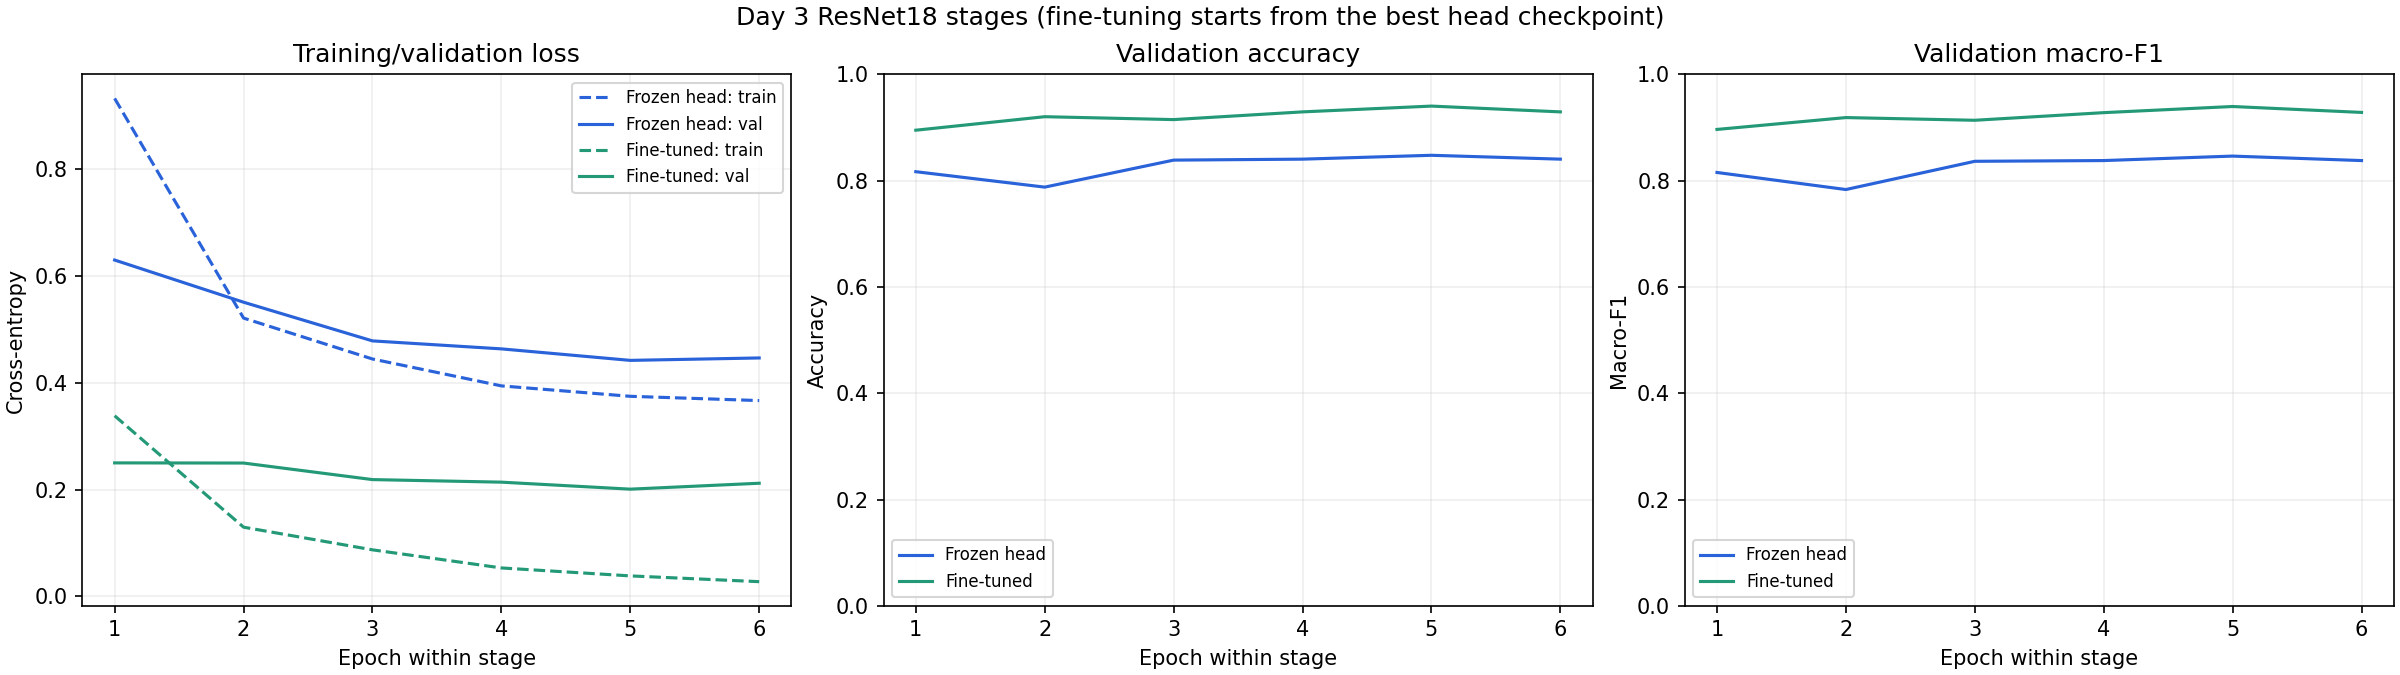

Selected using validation: resnet18_finetuned
Test set evaluated: False


In [17]:
import json
from IPython.display import Image as DisplayImage, Markdown, display

comparison = json.loads((experiment / "comparison.json").read_text())
rows = comparison["runs"]
table = ["| Model/run | Val accuracy | Val macro-F1 | Cumulative epochs | Cumulative minutes |",
         "|---|---:|---:|---:|---:|"]
for row in rows:
    table.append(f"| {row['run']} | {row['val_accuracy']:.2%} | {row['val_macro_f1']:.4f} | "
                 f"{row['cumulative_epoch_budget']} | {row['cumulative_seconds']/60:.1f} |")
display(Markdown("\n".join(table)))
display(DisplayImage(filename=str(experiment / "learning_curves.png")))
print("Selected using validation:", comparison["selected_by_validation"])
print("Test set evaluated:", comparison["test_evaluated"])

## 8. Inspect TensorBoard

Inspect training/validation loss, accuracy, and macro-F1 for both stages. Look
for fluctuations and gaps between training and validation performance. Scalar
logs and CSV histories are included in your backup.

In [18]:
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic("load_ext", "tensorboard")
    shell.run_line_magic("tensorboard", f"--logdir {experiment}")
else:
    print("TensorBoard logs are saved for viewing in Colab/Jupyter.")

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

## 9. Write your observations

Metrics are filled from your actual runs. Replace the two TODO explanations after
reviewing the table and curves, then rerun this cell. Report the observed result;
fine-tuning is not guaranteed to win every run.

In [19]:
my_observations.update({
    "what_improved_and_why": (
        "The best custom CNN achieved validation macro-F1 of 0.6740. "
        "The frozen ResNet18 head achieved 0.8460, and full fine-tuning "
        "improved this to 0.9393. These results are consistent with "
        "useful pretrained features and further adaptation to flower images. "
        "The different model architectures also affect this comparison."
    ),

    "stability_and_limitations": (
        "Training and validation losses decreased overall. Both ResNet18 "
        "stages achieved their best validation macro-F1 at epoch 5, "
        "then declined slightly at epoch 6 while training loss continued "
        "falling. This suggests possible late overfitting. "
        "Only one seed was tested. The frozen head received six epochs, "
        "while the fine-tuned model received a cumulative twelve-epoch "
        "budget. ResNet18 also benefited from prior ImageNet training."
    )
})

write_json(experiment / "day3_observations.json", my_observations)
print("Completed Day 3 observations saved.")

Completed Day 3 observations saved.


In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 10. Back up the models and results

After filling your observations, run this cell. The ZIP includes both ResNet18
checkpoints, both original CNN checkpoints, original splits, histories, plots,
TensorBoard logs, observations, environment records, and helper scripts.
It is larger than the Day 2 ZIP because it includes two ResNet18 models.

Keep **`day3_backup.zip`**. Also download this executed notebook from Colab's
top **File -> Download -> Download .ipynb** menu with outputs included.

In [21]:
exact_versions = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(experiment / "requirements-runtime.txt").write_text(exact_versions, encoding="utf-8")
backup = package_day3(ROOT, experiment)
print("Backup:", backup)
if IN_COLAB:
    from google.colab import files
    files.download(str(backup))

Backup: /content/flower-cnn/day3_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next: evaluation and Grad-CAM

Day 4 will examine per-class metrics, confusion patterns, and Grad-CAM explanations.
Use validation errors to choose improvements; keep final test comparisons separate.

Sources:
- [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [ResNet18 weights and preprocessing](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
- [Saving/loading weights](https://docs.pytorch.org/tutorials/beginner/basics/saveloadrun_tutorial.html)